# Lab 6: A solar panel on a cool spring morning, in depth

Sheet: *Apl. 3.3*, questions (a) to (e) on a solar panel.

# Part 0: How a PV module turns sunlight into electricity

## 0.1 The cell and the module

> **Semiconductor**: a material, such as silicon, whose electrons can be freed by energy (light, heat) but that does not conduct freely like a metal.

> **Photovoltaic (PV) effect**: light of sufficient energy frees electrons in a semiconductor, and an electric field built into the cell (at the boundary between two differently treated silicon layers) pushes them out as an electric current.

> **PV cell**: one slice of silicon that makes this effect. A single silicon cell gives only about 0.6 V.

> **PV module** (solar panel): a frame of cells wired **in series**, so the voltages add up while the same current flows through all of them. The module of the sheet is the Kyocera KD230GX-LPB (model name; Kyocera is the manufacturer).

## 0.2 Electrical quantities

> **Voltage** $U$ (volt, V): the electrical push between two terminals.

> **Current** $I$ (ampere, A): the flow of electric charge per second.

> **Power** $P$ (watt, W): the energy delivered per second, $P = U \cdot I$.

> **Direct current (DC)**: current that flows in one direction at a constant polarity; a PV module produces DC (a separate device, the inverter, converts it to the alternating current of the grid).

## 0.3 Sunlight and the reference test

> **Solar irradiance** $G$ (W/m²): the solar power arriving on one m² of the module surface. A clear noon gives roughly 1000 W/m²; clouds and low sun reduce it.

![From sunlight to electricity: the sun shines on a cell, many cells form a module and the module delivers voltage, current and power](images/pv-chain.svg)

*Figure: From sunlight to electricity: the sun shines on a cell, many cells form a module and the module delivers voltage, current and power*

> **Standard test conditions (STC)**: the laboratory conditions at which every module is rated: $G_{st} = 1000$ W/m², cells at $t_{c,st} = 25$ °C and a standard sunlight spectrum (the "air mass 1.5" spectrum, the colour mix of sunlight after crossing 1.5 atmosphere thicknesses). The subscript $st$ always means "at STC".

> **Rated power** $P_{M,st}$ (W): the maximum power of the module under STC. Here 230 W.

A real day differs from STC in two ways: the irradiance is not 1000 W/m², and the cells are not at 25 °C. The simplified model of the sheet turns each difference into a correction factor. The exercise measures how much each one costs on a spring morning.

# Part 1 (a): The cell temperature

## 1.1 Why the cell is hotter than the air

Most of the absorbed sunlight is not converted to electricity but to heat. The cell warms up until it loses that heat to the surrounding air. A stronger sun therefore gives a larger temperature gap between cell and air.

> **Air temperature** $t_a$ (°C): the temperature of the air around the module.

> **Cell temperature** $t_c$ (°C): the temperature of the cells; it controls the voltage and, slightly, the current.

> **Kelvin** (K): the unit of temperature difference; a difference of 1 K equals a difference of 1 °C.

> **NOCT** (nominal operating cell temperature, °C): the cell temperature a module reaches in a standard test with $G = 800$ W/m², $t_a = 20$ °C and a wind speed of 1 m/s. The manufacturer publishes it. Here NOCT = 45 °C, a 25 K rise at 800 W/m².

The model assumes that the rise is **proportional to the irradiance**, so the rise at 800 W/m² fixes the rise everywhere:

$$t_c = t_a + \frac{NOCT - 20}{800}\, G \qquad [\text{°C}]$$

with $G$ in W/m². The factor (45 − 20)/800 = 0.03125 K per W/m².

![Cell temperature as air temperature plus heating by the sun, for the spring morning and the hot noon](images/noct-rise.svg)

*Figure: Cell temperature as air temperature plus heating by the sun, for the spring morning and the hot noon*

In [1]:
import sys; sys.path.insert(0, "../../shared")
import numpy as np, matplotlib.pyplot as plt
from pv_module import *

plt.rcParams.update({"figure.figsize": (8, 4.2), "axes.grid": True, "grid.alpha": .3})

In [2]:
morning = operating_point(G_MORNING, TA_MORNING)
noon = operating_point(G_NOON, TA_NOON)

In [3]:
print(f"NOCT rise per W/m2: {(NOCT - 20) / 800:.5f} K")
print(f"Spring morning (G = {G_MORNING:.0f} W/m2, t_a = {TA_MORNING:.0f} °C): t_c = {morning['tc']:.3f} °C, {morning['tc'] - TC_ST:+.3f} K from the 25 °C reference")
print(f"Hot noon       (G = {G_NOON:.0f} W/m2, t_a = {TA_NOON:.0f} °C): t_c = {noon['tc']:.3f} °C, {noon['tc'] - TC_ST:+.3f} K from the 25 °C reference")

NOCT rise per W/m2: 0.03125 K
Spring morning (G = 500 W/m2, t_a = 12 °C): t_c = 27.625 °C, +2.625 K from the 25 °C reference
Hot noon       (G = 900 W/m2, t_a = 30 °C): t_c = 58.125 °C, +33.125 K from the 25 °C reference


## 1.2 Interpretation of $t_c$

* On the spring morning $t_c$ = **27.6 °C**: 15.6 K above the 12 °C air and only **2.6 K above the 25 °C of STC**. This small gap decides the whole exercise: the temperature corrections will be small.
* At the hot noon $t_c$ = 58.1 °C, 33.1 K above STC, so the corrections will be large.

> **Wind speed** $w$ (m/s): the speed of the air along the module. The sheet gives $w = 3$ m/s, but the NOCT formula has no wind term, so $w$ is not used.

The model ignores wind because NOCT was measured at one fixed, light wind. Real wind removes heat faster, so the real rise is smaller than the model's: for a windy day the model **overestimates** $t_c$, hence the temperature loss, slightly. The model also ignores that a module delivering power converts part of the light into electricity instead of heat, and the mounting (a roof-integrated module runs hotter than an open rack). These are the limits of a one-parameter model, acceptable for an exercise.

# Part 2 (b): Current and voltage at the operating conditions

## 2.1 The two corrections

> **Short-circuit current** $I_{sc}$ (A): the current through the module when its terminals are connected together (zero voltage). It is the largest current the module can give and is proportional to the irradiance.

> **Photocurrent** $I_L$ (A): the current generated by the light inside the cells. The simplified model sets $I_{sc} = I_L$.

> **Open-circuit voltage** $U_0$ (V): the voltage across the terminals when no current flows. It is the largest voltage the module can give.

> **Temperature coefficient** $\mu$: the change of a quantity per kelvin of cell temperature. The sheet gives $\mu_{I_{sc}} = +0.06$ %/°C of $I_{sc,st}$ and $\mu_{U_0} = -0.36$ %/°C of $U_{0,st}$.

> **Reference temperature** $t_{c,st}$ (°C): the cell temperature at which the STC values are valid, 25 °C. A coefficient multiplies the cell temperature **above 25 °C**, never above 0 °C.

$$I_L = \frac{G}{G_{st}}\left[ I_{sc,st} + \mu_{I_{sc}}\,(t_c - t_{c,st}) \right], \qquad I_{sc} = I_L$$

$$U_0 = U_{0,st} + \mu_{U_0}\,(t_c - t_{c,st})$$

The sheet gives $I_{sc,st} = 8.36$ A and $U_{0,st} = 36.9$ V. With the percent coefficients converted to absolute values, $\mu_{I_{sc}} = 0.0006 \cdot 8.36 = 0.005016$ A/K and $\mu_{U_0} = -0.0036 \cdot 36.9 = -0.13284$ V/K.

The current is **linear in $G$** (twice the photons, twice the electrons) and the open-circuit voltage is **independent of $G$** in this model. In a real cell $U_0$ falls slowly (logarithmically) when the light weakens, which the sheet neglects.

In [4]:
print(f"mu_Isc = {MU_ISC:+.6f} A/K,  mu_U0 = {MU_U0:+.5f} V/K")
print(f"Spring morning:  I_L = I_sc = {morning['i_l']:.4f} A   (G/G_st = {G_MORNING / G_ST:.2f})")
print(f"                 U_0        = {morning['u0']:.4f} V   ({morning['u0'] - U0_ST:+.4f} V from STC)")
print(f"Hot noon:        I_L = I_sc = {noon['i_l']:.4f} A,  U_0 = {noon['u0']:.4f} V")

mu_Isc = +0.005016 A/K,  mu_U0 = -0.13284 V/K
Spring morning:  I_L = I_sc = 4.1866 A   (G/G_st = 0.50)
                 U_0        = 36.5513 V   (-0.3487 V from STC)
Hot noon:        I_L = I_sc = 7.6735 A,  U_0 = 32.4997 V


## 2.2 Interpretation of $I_L$ and $U_0$

* **$I_L$ = 4.19 A**, almost exactly 50 % of 8.36 A. The sunlight is the whole story: the warm cells add only $+0.16$ % to the current.
* **$U_0$ = 36.55 V**, 0.35 V (0.95 %) below 36.9 V. A 2.6 K rise costs 0.95 % of the voltage but gains only 0.16 % of the current, so heat is always a net loss, about 0.3 % of power per K.
* At the hot noon the current is higher (7.67 A) but $U_0$ drops to 32.50 V, 11.9 % below STC.
* The coefficients are valid near STC (the sheet's linear model). Far from 25 °C the real curves bend.

# Part 3 (c): The module power

## 3.1 The I-V curve, the maximum power point and the fill factor

A module does not deliver $U_0$ and $I_{sc}$ at the same time: at zero voltage the current is largest but the power is zero, and at zero current the voltage is largest but the power is again zero.

> **Current-voltage (I-V) curve**: the graph of the current the module delivers at each voltage; it starts at $(0, I_{sc})$ and ends at $(U_0, 0)$.

> **Maximum power point (MPP)**: the point of the I-V curve where $U \cdot I$ is largest, the best operating point. A power electronic converter (MPP tracker) holds the module there.

> **Maximum power** $P_M$ (W): the power at the MPP, $P_M = U_{MPP} \cdot I_{MPP}$.

> **Fill factor** FF (dimensionless): the ratio of the maximum power to the ideal rectangle, $FF = \dfrac{P_M}{U_0 \cdot I_{sc}}$. A perfectly square curve would give FF = 1; real silicon modules are between 0.7 and 0.85. The sheet's 0.746 is checked below.

The simplified model keeps FF constant and uses it to get the power directly:

$$P_M = FF \cdot U_0 \cdot I_{sc}$$

![The I-V curve at STC and on the spring morning, with the maximum power point and the fill factor as an area ratio (schematic)](images/iv-curve.svg)

*Figure: The I-V curve at STC and on the spring morning, with the maximum power point and the fill factor as an area ratio (schematic)*

In [5]:
print(f"FF x U0,st x Isc,st = {FF * U0_ST * ISC_ST:.2f} W   (rated power {PM_ST:.0f} W: FF consistent with the sheet)")
print(f"Spring morning:  P_M = {morning['p_m']:.2f} W")
print(f"Hot noon:        P_M = {noon['p_m']:.2f} W")

FF x U0,st x Isc,st = 230.13 W   (rated power 230 W: FF consistent with the sheet)
Spring morning:  P_M = 114.16 W
Hot noon:        P_M = 186.04 W


## 3.2 Interpretation of $P_M$

* **$P_M$ = 114.2 W.** About the power of two ordinary light bulbs.
* The check $FF \cdot U_{0,st} \cdot I_{sc,st} = 230.1$ W reproduces the 230 W rating within 0.06 %, so the sheet's numbers are consistent.
* The constant-FF assumption is the weakest part of the model: in a real module FF falls when the cell is hot and at very low light, so the model slightly overestimates power in both situations.

# Part 4 (d): Which condition is closer to the rating?

## 4.1 Comparison with the hot noon

The percentage of the rating is $100\,P_M / P_{M,st}$, with the 230 W of the sheet. The model also factorises into two independent correction factors:

$$P_M = P_{M,st}\cdot \underbrace{\frac{G}{G_{st}}}_{f_G} \cdot \underbrace{\left(1 + \frac{\mu_{U_0}}{U_{0,st}}\Delta t\right)\left(1 + \frac{\mu_{I_{sc}}}{I_{sc,st}}\Delta t\right)}_{f_T}, \qquad \Delta t = t_c - t_{c,st}$$

where $f_G$ is the **sunlight factor** and $f_T$ the **temperature factor**.

> **Relative efficiency** (%): $100\,f_T$, the output per unit of sunlight relative to STC. 100 % means the module is as good as in the test; less is the cost of the hot cell.

For small $\Delta t$, $f_T \approx 1 - 0.003\,\Delta t$: **0.3 % of power is lost per K** above 25 °C.

In [6]:
for name, c in (("Spring morning", morning), ("Hot noon", noon)):
    dt = c["tc"] - TC_ST
    print(f"{name}: P_M = {c['p_m']:.1f} W = {c['percent_of_rated']:.1f} % of {PM_ST:.0f} W   (f_G = {c['g'] / G_ST:.2f}, f_T = {relative_efficiency(c['g'], c['tc']) / 100:.4f}, dt = {dt:+.1f} K)")
print("Power change at 1000 W/m2 for a cell at 35 / 45 / 60 °C: ",
      [f"{100 * (module_power(G_ST, t) / module_power(G_ST, TC_ST) - 1):.1f} %" for t in (35, 45, 60)])

Spring morning: P_M = 114.2 W = 49.6 % of 230 W   (f_G = 0.50, f_T = 0.9921, dt = +2.6 K)
Hot noon: P_M = 186.0 W = 80.9 % of 230 W   (f_G = 0.90, f_T = 0.8983, dt = +33.1 K)
Power change at 1000 W/m2 for a cell at 35 / 45 / 60 °C:  ['-3.0 %', '-6.1 %', '-10.8 %']


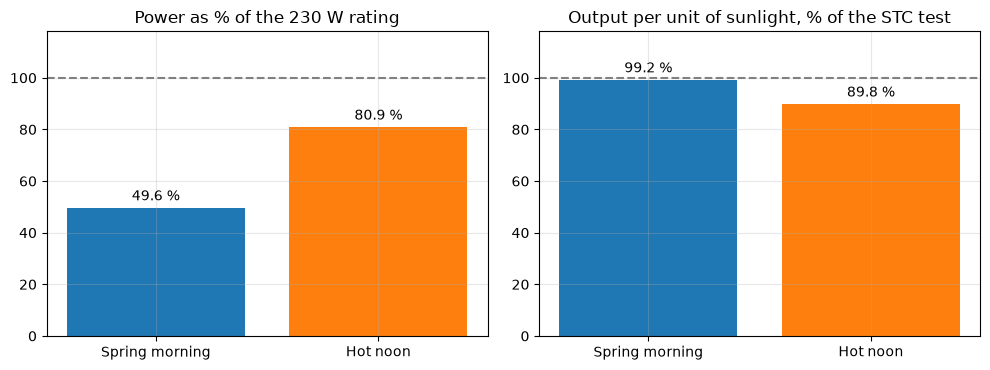

In [7]:
names = ["Spring morning", "Hot noon"]
cases = [morning, noon]
fig_, ax = plt.subplots(1, 2, figsize=(10, 3.8))
pct = [c["percent_of_rated"] for c in cases]
eff = [relative_efficiency(c["g"], c["tc"]) for c in cases]
for a_, vals, title in ((ax[0], pct, "Power as % of the 230 W rating"), (ax[1], eff, "Output per unit of sunlight, % of the STC test")):
    bars = a_.bar(names, vals, color=["tab:blue", "tab:orange"])
    a_.bar_label(bars, fmt="%.1f %%", padding=3)
    a_.axhline(100, ls="--", color="gray")
    a_.set(title=title, ylim=(0, 118))
plt.tight_layout(); plt.show()

*Figure: Left, the power as a share of the rating: the hot noon is closer. Right, the output per unit of sunlight: the spring morning is closer to the test.*

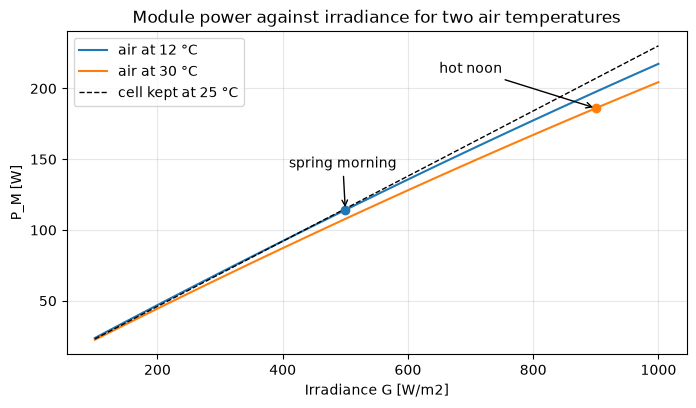

In [8]:
g_axis = np.linspace(100, 1000, 100)
fig_, ax = plt.subplots()
for ta, color in ((TA_MORNING, "tab:blue"), (TA_NOON, "tab:orange")):
    ax.plot(g_axis, module_power(g_axis, cell_temperature(g_axis, ta)), color=color, label=f"air at {ta:.0f} °C")
ax.plot(g_axis, module_power(g_axis, TC_ST), "k--", lw=1, label="cell kept at 25 °C")
ax.plot([G_MORNING], [morning["p_m"]], "o", color="tab:blue"); ax.annotate("spring morning", (G_MORNING, morning["p_m"]), (G_MORNING - 90, morning["p_m"] + 30), arrowprops=dict(arrowstyle="->"))
ax.plot([G_NOON], [noon["p_m"]], "o", color="tab:orange"); ax.annotate("hot noon", (G_NOON, noon["p_m"]), (G_NOON - 250, noon["p_m"] + 25), arrowprops=dict(arrowstyle="->"))
ax.set(xlabel="Irradiance G [W/m2]", ylabel="P_M [W]", title="Module power against irradiance for two air temperatures"); ax.legend(); plt.show()

*Figure: Module power against irradiance for two air temperatures. The hotter the air, the further the curve sags below the dashed 25 °C line, and the sag grows with the sunlight.*

## 4.2 Interpretation

* **The hot noon is closer to the rating: 80.9 %** (the sheet's "about 80 %") **against 49.6 %** on the spring morning. The sunlight factor decides: $f_G = 0.9$ against $0.5$.
* The temperature factor goes the other way: **$f_T = 0.992$ on the spring morning** (the cool module behaves like in the test) and **$f_T = 0.898$ at the hot noon**, a 10 % loss. $0.9 \times 0.898 = 0.808$ is the 80.9 %.
* So the spring morning is the **more efficient** condition and the hot noon the **more productive** one. A module is never at its rating unless both sunlight and temperature match STC, and the temperature factor can only be 1 for cool cells in strong sun (a cold, clear day).
* The dashed line in the figure is the module at 25 °C. The gap between it and each solid line is the temperature loss, and it grows with the irradiance, because stronger sun heats the cell more.

# Part 5 (e): Separating the irradiance and temperature effects

## 5.1 The definition

> **Irradiance effect**: the power lost because the irradiance is below $G_{st}$, with the cell at $t_{c,st}$.

> **Temperature effect**: the power lost because the cell is not at $t_{c,st}$.

Because $P_M = P_{M,st}\, f_G f_T$, the two effects **multiply**, so the drop $P_{M,st}(1 - f_G f_T)$ cannot be split in a way independent of the order. Three conventions are shown. In every one, the model's STC power 230.1 W is the starting point (the 230 W on the label is rounded).

* **Sunlight first**: STC → $(G,\ 25\,°C)$ → $(G,\ t_c)$. Irradiance effect $P_{M,st}(1-f_G)$; temperature effect $P_{M,st} f_G (1-f_T)$.
* **Heat first**: STC → $(G_{st},\ t_c)$ → $(G,\ t_c)$. Temperature effect $P_{M,st}(1-f_T)$; irradiance effect $P_{M,st} f_T (1-f_G)$.
* **Logarithmic**: the drop is shared in proportion to $\ln f_G$ and $\ln f_T$. It does not depend on the order, because the logarithm turns the product into a sum.

In [9]:
for name, (g, ta) in (("Spring morning", (G_MORNING, TA_MORNING)), ("Hot noon", (G_NOON, TA_NOON))):
    s = loss_split(g, ta)
    a, b, l = s["irradiance_first"], s["temperature_first"], s["log"]
    print(f"{name}: drop {s['drop']:.2f} W from {s['p_stc']:.2f} W to {s['p_m']:.2f} W")
    print(f"   sunlight first : irradiance {a['irradiance']:.2f} W + temperature {a['temperature']:.2f} W")
    print(f"   heat first     : temperature {b['temperature']:.2f} W + irradiance {b['irradiance']:.2f} W")
    print(f"   logarithmic    : irradiance {l['irradiance']:.2f} W + temperature {l['temperature']:.2f} W")

Spring morning: drop 115.97 W from 230.13 W to 114.16 W
   sunlight first : irradiance 115.06 W + temperature 0.91 W
   heat first     : temperature 1.82 W + irradiance 114.16 W
   logarithmic    : irradiance 114.66 W + temperature 1.31 W
Hot noon: drop 44.09 W from 230.13 W to 186.04 W
   sunlight first : irradiance 23.01 W + temperature 21.07 W
   heat first     : temperature 23.41 W + irradiance 20.67 W
   logarithmic    : irradiance 21.84 W + temperature 22.24 W


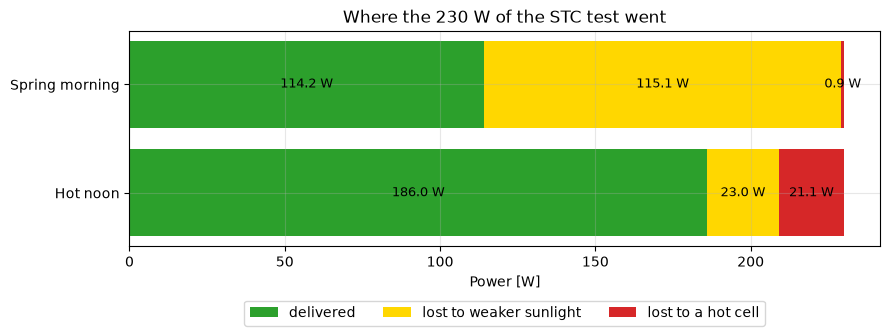

In [10]:
fig_, ax = plt.subplots(figsize=(9, 3.6))
for i, (name, (g, ta)) in enumerate((("Spring morning", (G_MORNING, TA_MORNING)), ("Hot noon", (G_NOON, TA_NOON)))):
    s = loss_split(g, ta)
    parts = [s["p_m"], s["irradiance_first"]["irradiance"], s["irradiance_first"]["temperature"]]
    left = 0
    for part, color, label in zip(parts, ("tab:green", "gold", "tab:red"), ("delivered", "lost to weaker sunlight", "lost to a hot cell")):
        ax.barh(i, part, left=left, color=color, label=label if i == 0 else None)
        ax.text(left + part / 2, i, f"{part:.1f} W", ha="center", va="center", fontsize=9)
        left += part
ax.set(yticks=[0, 1], yticklabels=["Spring morning", "Hot noon"], xlabel="Power [W]", title="Where the 230 W of the STC test went")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=3); ax.invert_yaxis(); plt.tight_layout(); plt.show()

*Figure: Where the 230 W of the STC test went on the two days (sunlight first)*

## 5.2 Interpretation

* **Spring morning: about 115 W of the 116 W drop (99 %) is the weaker sunlight.** The temperature effect is only **0.9 W** (sunlight first), **1.8 W** (heat first) or **1.3 W** (logarithmic): under 2 % of the drop in every convention. The conclusion does not depend on the convention.
* **Hot noon: the two effects are of the same size**, 21 to 23 W each out of 44 W, with the temperature effect slightly larger in the logarithmic split (22.2 W against 21.8 W).
* The temperature effect is the same few tenths of a percent per kelvin in both cases; what changes is the number of kelvin above 25 °C: 2.6 K on the morning, 33.1 K at noon.

## 5.3 The reference-temperature pitfall

Using 0 °C instead of 25 °C as $t_{c,st}$ would count 27.6 K instead of 2.6 K of heating on the morning.

In [11]:
tc = morning["tc"]
wrong = FF * (U0_ST + MU_U0 * tc) * (G_MORNING / G_ST * (ISC_ST + MU_ISC * tc))
print(f"With t_c,st = 0 °C by mistake: P_M = {wrong:.1f} W instead of {morning['p_m']:.1f} W ({100 * (wrong / morning['p_m'] - 1):+.1f} %)")

With t_c,st = 0 °C by mistake: P_M = 105.3 W instead of 114.2 W (-7.7 %)


The mistake underestimates the power by 7.7 % and would make the temperature effect look about ten times larger than it is.

# Part 6: Limits of the model and summary

## 6.1 What the simplified model ignores

* Wind and mounting (NOCT is measured at one wind speed and one mounting).
* A fill factor that depends on temperature and light.
* The slow fall of $U_0$ with the light level, and spectrum and incidence-angle effects.
* Shading, dirt, ageing and the losses of the converter between module and grid.

For the question asked, a spring morning at 2.6 K above STC, none of these changes the conclusion: the sunlight dominates.

## 6.2 Summary of the answers

* **(a)** $t_c = 27.6$ °C.
* **(b)** $I_L = I_{sc} = 4.19$ A and $U_0 = 36.55$ V.
* **(c)** $P_M = 114.2$ W.
* **(d)** 49.6 % of the rating, against 80.9 % at the hot noon. The hot noon is closer, because its sunlight factor (0.9) is much higher than 0.5; the spring morning is the more efficient one ($f_T = 0.992$ against 0.898).
* **(e)** About 115 W of the 116 W drop is due to the lower irradiance and 0.9 to 1.8 W (depending on the order) to the cell temperature.